# Module scores, group distributions and confusion matrices

This tutorial covers three small but heavily used ArchR utilities and their Epione ports:

| ArchR | Epione | What it does |
|---|---|---|
| `addModuleScore` | `epi.tl.add_module_score` | per-cell score of a gene set, normalised against signal-matched background genes |
| `plotGroups` / `ggGroup` | `epi.pl.plot_groups` | ridge or violin plots of a per-cell value across groups |
| `confusionMatrix` | `epi.tl.confusion_matrix` (+ `epi.pl.plot_confusion_matrix`) | cross-tabulation of two labelings |

All three were rebuilt from the ArchR 1.0.3 source and checked number-for-number against ArchR on the
ArchR hematopoiesis tutorial data (10,660 cells from BMMC, CD34+ BMMC and PBMC). The last section shows that comparison.

## Load the data

We use the gene score matrix of the ArchR hematopoiesis tutorial project (`getTutorialData("Hematopoiesis")`,
exported from the ArchR project with `getMatrixFromProject(proj, "GeneScoreMatrix")`), plus the per-cell metadata
(`Sample`, `Clusters`, `TSSEnrichment`, UMAP coordinates). Any cells x genes AnnData works the same way.

In [1]:
import pathlib, warnings
warnings.filterwarnings('ignore', category=DeprecationWarning)
import numpy as np
import pandas as pd
import scipy.io as sio
import anndata as ad
import matplotlib.pyplot as plt
from IPython.display import display
import epione as epi

FIXTURE = pathlib.Path('/scratch/users/steorra/analysis/25_epione/epione_dev/fixture')
TABLES = FIXTURE / 'tables'

X = sio.mmread(TABLES / 'GeneScoreMatrix.mtx').T.tocsr()          # cells x genes
cells = (TABLES / 'GeneScoreMatrix_cells.txt').read_text().split()
genes = pd.read_csv(TABLES / 'GeneScoreMatrix_features.tsv', sep='\t')
obs = pd.read_csv(TABLES / 'cells.tsv', sep='\t', index_col=0).loc[cells]
adata = ad.AnnData(X, obs=obs, var=genes.set_index(genes['name'].astype(str).values))
adata.var_names_make_unique()
adata.obsm['X_umap'] = adata.obs[['UMAP1', 'UMAP2']].values
adata

AnnData object with n_obs × n_vars = 10660 × 23127
    obs: 'Sample', 'TSSEnrichment', 'ReadsInTSS', 'ReadsInPromoter', 'ReadsInBlacklist', 'PromoterRatio', 'PassQC', 'NucleosomeRatio', 'nMultiFrags', 'nMonoFrags', 'nFrags', 'nDiFrags', 'BlacklistRatio', 'Clusters', 'ReadsInPeaks', 'FRIP', 'UMAP1', 'UMAP2'
    var: 'seqnames', 'start', 'end', 'strand', 'name', 'idx'
    obsm: 'X_umap'

## Confusion matrix

`epi.tl.confusion_matrix(i, j)` counts cells for every pair of labels. Rows and columns keep the order in which
labels first appear, exactly like ArchR's `confusionMatrix`. Here we ask which samples contribute to each cluster.

In [2]:
cm = epi.tl.confusion_matrix(adata.obs['Clusters'], adata.obs['Sample'])
cm

,scATAC_BMMC_R1,scATAC_CD34_BMMC_R1,scATAC_PBMC_R1
C10,321,512,2
C4,191,2,74
C2,362,1,0
C6,267,6,170
C7,406,0,1093
C5,1490,6,1028
C11,184,1754,0
C8,1229,0,64
C9,238,630,12
C1,162,145,10


The ArchR tutorial normalises each row to fractions before plotting. `epi.pl.plot_confusion_matrix` does that with
`normalize='row'` and uses ArchR's `whiteBlue` colours. The progenitor-like clusters C9-C11 come mainly from the
CD34+ sample, the T-cell cluster C7 mostly from PBMC, while clusters such as C5 and C6 mix BMMC and PBMC cells.

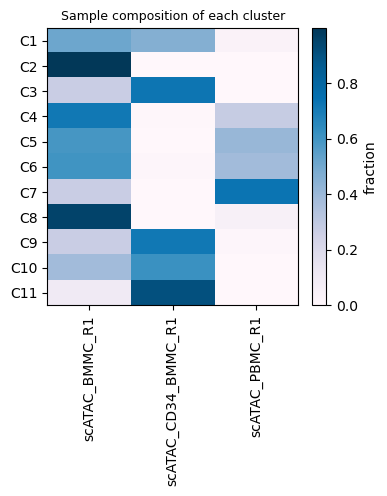

In [3]:
order = sorted(cm.index, key=lambda s: int(s[1:]))
fig = epi.pl.plot_confusion_matrix(cm.loc[order], normalize='row', figsize=(3.6, 3.6))
fig.axes[0].set_title('Sample composition of each cluster', fontsize=9)
plt.show()

## Module scores

A module score summarises a gene set in one number per cell:

$$\text{score}_c = \frac{1}{|F|}\sum_{f\in F} x_{fc} \;-\; \frac{1}{|B|}\sum_{b\in B} x_{bc}$$

where $F$ are the module genes and $B$ the background genes. All genes are ranked by total signal and cut into
`n_bin` equal-size bins (genes with zero signal form bin 0). For every module gene, `n_bgd` background genes are drawn
from the matching signal bin, so the background has the same overall signal level as the module.

Two details matter for exact agreement with ArchR:

* **Sampling** uses an exact emulation of R's random number generator, so `seed=1` draws the same background genes
  as ArchR's `seed = 1`.
* **Gene totals.** ArchR ranks genes by the row sums it stored per sample (one Arrow file per sample). Passing
  `sample_key='Sample'` reproduces those sums bit for bit. Without it, floating-point rounding can reorder a handful
  of near-tied genes, so a few background genes differ (the scores still correlate at r > 0.999).

In [4]:
modules = {
    'B': ['MS4A1', 'CD79A', 'PAX5'],
    'T': ['CD3D', 'CD3E', 'CD2'],
    'Mono': ['CD14', 'LYZ', 'CEBPB'],
    'Erythroid': ['GATA1', 'KLF1', 'HBB'],
    'Progenitor': ['CD34'],
}
scores = epi.tl.add_module_score(adata, modules, n_bin=25, n_bgd=100, seed=1, sample_key='Sample')
scores.head()

Module.B: 3 features, 300 background features
Module.Erythroid: 3 features, 300 background features


Module.Mono: 3 features, 300 background features
Module.Progenitor: 1 features, 100 background features


Module.T: 3 features, 300 background features


,Module.B,Module.T,Module.Mono,Module.Erythroid,Module.Progenitor
barcode,,,,,
scATAC_BMMC_R1#TTATGTCAGTGATTAG-1,-0.245890,0.341833,0.100380,-0.320853,-0.11179
scATAC_BMMC_R1#AAGATAGTCACCGCGA-1,-0.352923,0.502567,-0.449083,-0.330213,-0.48659
scATAC_BMMC_R1#GCATTGAAGATTCCGT-1,-0.344087,-0.511170,-0.476860,-0.228223,-0.38822
scATAC_BMMC_R1#TATGTTCAGGGTTCCC-1,0.351080,-0.500353,-0.431753,-0.316203,-0.31384
scATAC_BMMC_R1#TCCATCGGTCCCGTGA-1,0.019017,-0.395570,0.167597,-0.314837,0.33269


Mean score per cluster. Each module is highest in the expected clusters: B in C2, C3 and C6, T in C7 and C8,
Mono in C4 and C5, Erythroid in C9, and Progenitor (CD34) in C9-C11.

In [5]:
order = sorted(adata.obs['Clusters'].unique(), key=lambda s: int(s[1:]))
summary = scores.groupby(adata.obs['Clusters'].values).mean().loc[order]
display(summary.round(2).style.background_gradient(cmap='RdBu_r', axis=0))

,Module.B,Module.T,Module.Mono,Module.Erythroid,Module.Progenitor
C1,-0.020000,-0.010000,-0.120000,-0.070000,0.100000
C2,0.900000,-0.190000,-0.200000,-0.060000,-0.030000
C3,0.850000,-0.100000,-0.240000,-0.110000,0.090000
C4,0.010000,0.040000,0.660000,-0.000000,-0.020000
C5,-0.210000,-0.220000,1.220000,0.020000,0.040000
C6,1.320000,-0.210000,-0.150000,0.070000,-0.190000
C7,-0.040000,0.440000,-0.060000,0.060000,-0.270000
C8,0.010000,0.850000,-0.010000,0.190000,-0.100000
C9,-0.110000,-0.150000,0.150000,0.410000,0.350000
C10,0.020000,-0.150000,0.360000,0.020000,0.370000


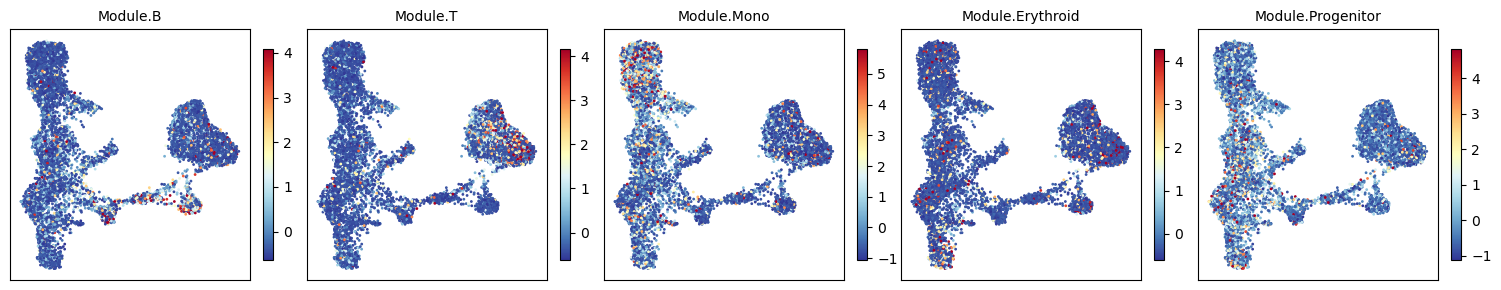

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for ax, col in zip(axes, scores.columns):
    v = scores[col].values
    lo, hi = np.quantile(v, [0.01, 0.99])
    sc = ax.scatter(adata.obs['UMAP1'], adata.obs['UMAP2'], c=np.clip(v, lo, hi), s=1,
                    cmap='RdYlBu_r', rasterized=True)
    ax.set_title(col, fontsize=10); ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(sc, ax=ax, fraction=0.04)
plt.tight_layout(); plt.show()

Parameters and the background genes that were drawn are stored in `adata.uns['module_score']`:

In [7]:
info = adata.uns['module_score']
print(info['params'])
print('B module genes      :', info['features']['Module.B'])
print('first 10 background :', info['background']['Module.B'][:10])

{'n_bin': 25, 'n_bgd': 100, 'seed': 1, 'layer': None, 'sample_key': 'Sample', 'archr_bin_indexing': True}
B module genes      : ['MS4A1', 'CD79A', 'PAX5']
first 10 background : ['MIR1260A', 'CCL8', 'GJA5', 'EPHA8', 'PHYHD1', 'RNF17', 'FZD10', 'SLITRK3', 'PYDC2', 'MIR34C']


### ArchR 1.0.3 behaviours worth knowing

Porting from source turned up three behaviours of ArchR 1.0.3's `addModuleScore` for gene-name modules:

1. **Background bin offset.** ArchR looks up each gene's background pool with `binList[bin]`, which indexes the list
   *by position*. When genes with zero signal exist (245 here), position `k` holds bin `k-1`, so background genes come
   from the next-lower signal bin. Epione reproduces this by default (`archr_bin_indexing=True`) and offers
   `archr_bin_indexing=False` to sample from the gene's own bin.
2. **Several multi-gene modules in one call** fail (`5 elements in value to replace 13`) or, when the gene count is a
   multiple of the module count, silently assign genes to the wrong module. Epione assigns every gene to its own module.
3. **One-gene modules** (like `Progenitor = CD34`) fail in ArchR with a `colMeans` error. Epione handles them.

In all cases where ArchR runs correctly, the Epione result is identical; for 2 and 3 we compared against ArchR with a
two-token fix (see the parity section).

In [8]:
own_bin = epi.tl.add_module_score(adata, modules, seed=1, sample_key='Sample', archr_bin_indexing=False,
                                  inplace=False, verbose=False)
print('Pearson r, ArchR-style vs own-bin background:')
print(pd.Series({c: np.corrcoef(scores[c], own_bin[c])[0, 1] for c in scores.columns}).round(4))

Pearson r, ArchR-style vs own-bin background:
Module.B             0.9937
Module.T             0.9946
Module.Mono          0.9915
Module.Erythroid     0.9904
Module.Progenitor    0.9808
dtype: float64


## Group distributions with `plot_groups`

`epi.pl.plot_groups` draws one distribution per group for an `obs` column or a gene. It follows ArchR's `plotGroups`
step by step:

* each group is down-sampled to `max_cells` (1000) cells with R-compatible sampling (`seed=1` = `set.seed(1)`),
* values are clipped to the 0.2-99.8 % quantiles of the sampled cells (`quant_cut`),
* ridge plots order groups by reverse "mixed" sort (C11 ... C2, C1); violins by mixed sort,
* colours follow ArchR's `stallion` palette.

TSS enrichment per sample, as ridges:

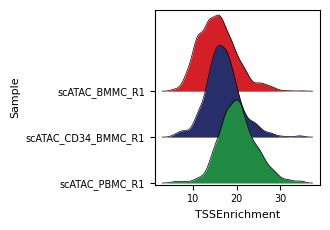

In [9]:
fig = epi.pl.plot_groups(adata, group_by='Sample', name='TSSEnrichment', plot_as='ridges', figsize=(3.4, 2.4))
plt.show()

Gene scores per cluster. As in ArchR, several genes can be passed at once; the same sampled cells are used for all of them.

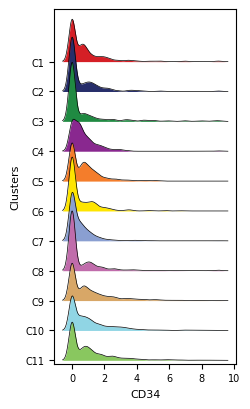

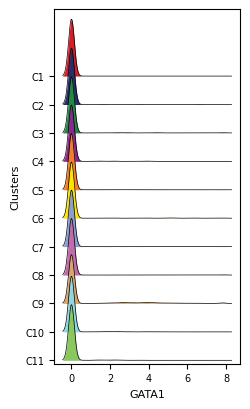

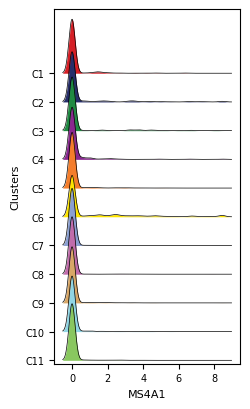

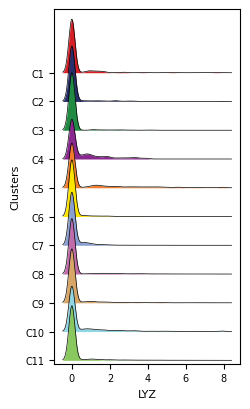

In [10]:
figs = epi.pl.plot_groups(adata, group_by='Clusters', name=['CD34', 'GATA1', 'MS4A1', 'LYZ'], plot_as='ridges',
                          figsize=(2.6, 4.2))
plt.show()

Violin + box plots of the module scores:

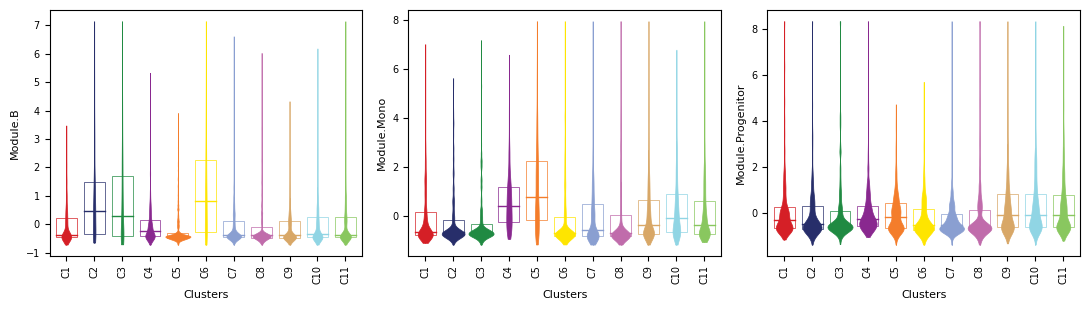

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, col in zip(axes, ['Module.B', 'Module.Mono', 'Module.Progenitor']):
    epi.pl.plot_groups(adata, group_by='Clusters', name=col, plot_as='violin', ax=ax)
plt.tight_layout(); plt.show()

`return_data=True` gives the numbers behind a plot: the sampled cells, the clipped values, the group order, and the
density / box statistics that were drawn.

In [12]:
fig, d = epi.pl.plot_groups(adata, group_by='Clusters', name='Module.T', plot_as='violin', return_data=True)
plt.close(fig)
display(d['box'].round(3))

,group,x,ymin,lower,middle,upper,ymax,n
0,C1,1,-0.644,-0.466,-0.366,0.140,1.004,317
1,C2,2,-0.723,-0.494,-0.426,-0.298,-0.045,363
2,C3,3,-0.730,-0.494,-0.413,-0.269,0.053,301
3,C4,4,-0.603,-0.420,-0.224,0.347,1.435,267
4,C5,5,-0.730,-0.456,-0.393,-0.253,0.051,1000
5,C6,6,-0.674,-0.455,-0.394,-0.304,-0.091,443
6,C7,7,-0.730,-0.385,0.106,0.982,3.016,1000
7,C8,8,-0.730,-0.411,-0.225,1.820,5.042,1000
8,C9,9,-0.730,-0.448,-0.370,-0.135,0.315,880
9,C10,10,-0.730,-0.456,-0.383,-0.154,0.298,835


## Parity vs ArchR

The R script `tests/parity/module_score_groups/r_reference.R` runs ArchR 1.0.3 on the same project and dumps
`confusionMatrix`, `addModuleScore` (including the background genes ArchR drew) and the data that `ggplot_build()`
extracts from `plotGroups` figures. `tests/parity/module_score_groups/py_parity.py` compares every output with the
gate pre-registered in `MANIFEST.md` (thresholds fixed before the first comparison).

Module-score references:

* **official**: unmodified ArchR, one call per multi-gene module (the only configuration ArchR handles correctly);
* **patched_all**: all five modules in one call, with ArchR's two module-assignment bugs fixed by two tokens.

Every config is run twice: once with ArchR's background genes injected, once free-running with the same seed.

In [13]:
import sys, json
REPO = pathlib.Path(epi.__file__).resolve().parents[1]
sys.path.insert(0, str(REPO / 'tests' / 'parity' / 'module_score_groups'))
import py_parity as pp

REF = pathlib.Path('/scratch/users/steorra/analysis/25_epione/epione_dev/work/module-score-groups/ref_v2')
rs = pd.read_csv(REF / 'gs_rowsums.tsv', sep='\t')
arrow_sums = pp.arrow_rowsums(FIXTURE / 'ArchR_base' / 'ArrowFiles', rs.seqnames.unique())
fresh = pp.load_gene_scores(TABLES)
report = dict(confusion=pp.confusion_parity(fresh, REF),
              binning=pp.binning_parity(fresh, REF, arrow_sums),
              module_score=pp.module_score_parity(fresh, REF),
              plot_groups=pp.plot_groups_parity(fresh, REF))
print('confusionMatrix:', report['confusion'])
print('gene totals    :', report['binning'])

confusionMatrix: {'same_order': True, 'max_abs': 0.0}
gene totals    : {'rowsums_vs_tsv15_max_rel': 2.3186118771677603e-15, 'order_sample_vs_global_npos': 20, 'sample_sums_equal_arrow_bitwise': True, 'global_sums_equal_arrow_bitwise': False, 'global_sums_n_bitdiff': 20871}


In [14]:
ms = pd.DataFrame(report['module_score']).set_index('config')
ms.columns = ['background identical', 'max|Δ| injected', 'max|Δ| free (sample_key)', 'max|Δ| free (no sample_key)',
              'min Pearson (no sample_key)']
display(ms)

,background identical,max|Δ| injected,max|Δ| free (sample_key),max|Δ| free (no sample_key),min Pearson (no sample_key)
config,,,,,
official_B_nbin25_nbgd100_seed1,True,3.197442e-14,3.197442e-14,1.191633e-01,0.999971
official_T_nbin25_nbgd100_seed1,True,3.552714e-14,3.552714e-14,3.552714e-14,1.000000
official_Mono_nbin25_nbgd100_seed1,True,3.552714e-14,3.552714e-14,3.552714e-14,1.000000
official_Erythroid_nbin25_nbgd100_seed1,True,3.197442e-14,3.197442e-14,3.197442e-14,1.000000
patched_all_nbin25_nbgd100_seed1,True,3.552714e-14,3.552714e-14,5.478000e-01,0.999815
official_B_nbin25_nbgd25_seed7,True,3.197442e-14,3.197442e-14,4.766533e-01,0.999630
official_T_nbin25_nbgd25_seed7,True,3.375078e-14,3.375078e-14,4.761600e-01,0.999626
official_Mono_nbin25_nbgd25_seed7,True,3.552714e-14,3.552714e-14,3.552714e-14,1.000000
official_Erythroid_nbin25_nbgd25_seed7,True,3.552714e-14,3.552714e-14,3.552714e-14,1.000000


In [15]:
pg = pd.DataFrame(report['plot_groups']).set_index('case')
display(pg)

,cells_exact,values_max_abs,groups_exact,levels_exact,density_max_abs,box_max_abs
case,,,,,,
gs_CD34_ridges,True,3.552714e-15,True,True,5.151435e-14,NaN
gs_CD34_violin,True,3.552714e-15,True,True,7.105427e-15,1.110223e-16
gs_GATA1_ridges,True,8.881784e-16,True,True,4.973799e-14,NaN
gs_GATA1_violin,True,8.881784e-16,True,True,1.376677e-14,0.000000e+00
gs_MS4A1_ridges,True,1.776357e-15,True,True,5.861978e-14,NaN
gs_MS4A1_violin,True,1.776357e-15,True,True,2.131628e-14,0.000000e+00
gs_LYZ_ridges,True,3.552714e-15,True,True,5.151435e-14,NaN
gs_LYZ_violin,True,3.552714e-15,True,True,6.217249e-15,0.000000e+00
tss_sample_ridges,True,2.842171e-14,True,True,5.329071e-14,NaN


In [16]:
gates = [
    ('confusionMatrix counts + order', '1 strict', '== 0', report['confusion']['max_abs'] == 0 and report['confusion']['same_order']),
    ('feature totals (sample_key) == Arrow rowSums', '1 strict', 'bitwise', report['binning']['sample_sums_equal_arrow_bitwise']),
    ('background genes (free-running)', '1 strict', 'identical', bool(ms['background identical'].all())),
    ('module score, ArchR draws injected', '1', '<= 1e-8', ms['max|Δ| injected'].max()),
    ('module score, free-running', '1', '<= 1e-8', ms['max|Δ| free (sample_key)'].max()),
    ('plotGroups sampled cells / groups / order', '1 strict', 'identical', bool((pg.cells_exact & pg.groups_exact & pg.levels_exact).all())),
    ('plotGroups values after quantCut', '1', '<= 1e-8', pg.values_max_abs.max()),
    ('ridge / violin densities', '1 bounded', '<= 1e-6', pg.density_max_abs.max()),
    ('box statistics', '1', '<= 1e-8', pg.box_max_abs.max()),
]
fmt = lambda v: ('pass' if v else 'FAIL') if isinstance(v, (bool, np.bool_)) else f'{v:.2e}'
display(pd.DataFrame([(o, c, g, fmt(v)) for o, c, g, v in gates], columns=['output', 'class', 'gate', 'value']))

,output,class,gate,value
0,confusionMatrix counts + order,1 strict,== 0,pass
1,feature totals (sample_key) == Arrow rowSums,1 strict,bitwise,pass
2,background genes (free-running),1 strict,identical,pass
3,"module score, ArchR draws injected",1,<= 1e-8,3.55e-14
4,"module score, free-running",1,<= 1e-8,3.55e-14
5,plotGroups sampled cells / groups / order,1 strict,identical,pass
6,plotGroups values after quantCut,1,<= 1e-8,2.84e-14
7,ridge / violin densities,1 bounded,<= 1e-6,5.86e-14
8,box statistics,1,<= 1e-8,1.78e-15


All gates pass with errors at the 1e-14 level (floating-point rounding). The only non-exact numbers are the
`no sample_key` columns, the documented convenience mode in which gene totals are summed over all cells at once.

Visual comparison: Epione vs ArchR module scores (free-running, `seed=1`), and the CD34 ridge densities that ggplot2
drew in ArchR overlaid on Epione's.

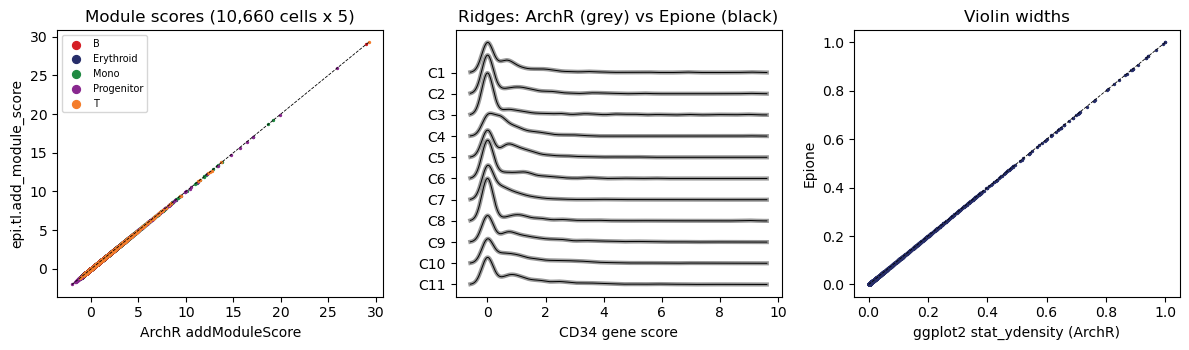

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
ref = pp._scores(REF, 'patched_all_nbin25_nbgd100_seed1').loc[fresh.obs_names]
mine = epi.tl.add_module_score(fresh, modules, seed=1, sample_key='Sample', inplace=False, verbose=False)
for col, c in zip(ref.columns, ['#D51F26', '#272E6A', '#208A42', '#89288F', '#F47D2B']):
    axes[0].scatter(ref[col], mine[col], s=2, color=c, label=col.split('.')[1], rasterized=True)
axes[0].plot(*[[ref.values.min(), ref.values.max()]] * 2, 'k--', lw=0.6)
axes[0].set_xlabel('ArchR addModuleScore'); axes[0].set_ylabel('epi.tl.add_module_score')
axes[0].legend(markerscale=4, fontsize=7); axes[0].set_title('Module scores (10,660 cells x 5)')

d = epi.pl._groups.group_plot_data(fresh, 'Clusters', 'CD34', plot_as='ridges', seed=1)
r = pd.read_csv(REF / 'pg_gs_CD34_ridges_layer1.tsv', sep='\t')
for y, g in d['ridges'].groupby('y'):
    rg = r[(r.y == y) & (r.datatype == 'ridgeline')]
    axes[1].plot(rg.x, rg.ymax, color='0.6', lw=3)
    axes[1].plot(g.x, g.ymax, color='k', lw=0.7)
axes[1].set_yticks(range(1, len(d['levels']) + 1)); axes[1].set_yticklabels(d['levels'])
axes[1].set_xlabel('CD34 gene score'); axes[1].set_title('Ridges: ArchR (grey) vs Epione (black)')

v = epi.pl._groups.group_plot_data(fresh, 'Clusters', 'CD34', plot_as='violin', seed=1)
l1 = pd.read_csv(REF / 'pg_gs_CD34_violin_layer1.tsv', sep='\t')
axes[2].scatter(l1.sort_values(['x', 'y']).violinwidth, v['violin'].sort_values(['x', 'y']).violinwidth, s=2, color='#272E6A')
axes[2].plot([0, 1], [0, 1], 'k--', lw=0.6)
axes[2].set_xlabel('ggplot2 stat_ydensity (ArchR)'); axes[2].set_ylabel('Epione'); axes[2].set_title('Violin widths')
plt.tight_layout(); plt.show()

### Reproducing the comparison

```bash
Rscript tests/parity/module_score_groups/r_reference.R <ArchRProject dir> <ref dir>
python  tests/parity/module_score_groups/py_parity.py <fixture tables dir> <ref dir> report.json
```

Versions used here: R 4.4.3, ArchR 1.0.3, ggplot2 4.0.3, ggridges 0.5.7.